<a href="https://colab.research.google.com/github/aic309/PCD_Assignment_3/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCD Assignment 03
**Segmentation + Morphology**

- Segmentation: **Otsu thresholding**
- Morphology: **erosion, dilation, opening, closing**




In [41]:
import random
import matplotlib.pyplot as plt
from PIL import Image

## 2. Load image


In [42]:
IMAGE_PATH = "3_cells.png"
MAX_WIDTH = 250

def resize(img, new_w):
    h, w = len(img), len(img[0])
    if w <= new_w:
        return img
    new_h = int(h * new_w / w)
    return [[img[int(y*h/new_h)][int(x*w/new_w)] for x in range(new_w)]
            for y in range(new_h)]

gt = None
try:
    pil = Image.open(IMAGE_PATH).convert("RGB")
    w, h = pil.size
    pix = pil.load()
    gray_src = []
    for y in range(h):
        row = []
        for x in range(w):
            r, g, b = pix[x, y]
            row.append(int(0.299*r + 0.587*g + 0.114*b))
        gray_src.append(row)
    gray = resize(gray_src, MAX_WIDTH)
    print("Loaded", IMAGE_PATH, "->", len(gray[0]), "x", len(gray))
except Exception:
    print("Image not found -> using synthetic test image")
    random.seed(0)
    H, W = 150, 150
    def inside(x, y):
        return ((x-45)**2 + (y-50)**2 < 24**2 or (x-105)**2 + (y-45)**2 < 18**2
                or (abs(x-75) < 30 and abs(y-110) < 15))
    gt = [[1 if inside(x, y) else 0 for x in range(W)] for y in range(H)]
    gray = []
    for y in range(H):
        row = []
        for x in range(W):
            v = (170 if gt[y][x] else 70) + random.gauss(0, 40)
            r = random.random()
            if r < 0.02: v = 0
            elif r > 0.98: v = 255
            row.append(int(min(255, max(0, v))))
        gray.append(row)

Loaded 3_cells.png -> 250 x 200


## 3. Grayscale
$$Y = 0.299R + 0.587G + 0.114B$$

## 4. Segmentation: Otsu threshold

$$\sigma_b^2(t) = w_0(t)\,w_1(t)\,[\mu_0(t)-\mu_1(t)]^2$$

In [43]:
def otsu_threshold(img):
    hist = [0] * 256
    for row in img:
        for v in row:
            hist[v] += 1
    total = sum(hist)
    p = [c / total for c in hist]

    best_t, best_var = 0, -1
    for t in range(256):
        w0 = sum(p[:t+1])
        w1 = 1 - w0
        if w0 == 0 or w1 == 0:
            continue
        mu0 = sum(i * p[i] for i in range(t+1)) / w0
        mu1 = sum(i * p[i] for i in range(t+1, 256)) / w1
        var_b = w0 * w1 * (mu0 - mu1) ** 2
        if var_b > best_var:
            best_var, best_t = var_b, t
    return best_t

def segment(img):
    t = otsu_threshold(img)
    return [[1 if v > t else 0 for v in row] for row in img], t

seg, t = segment(gray)
print("Otsu threshold =", t)

Otsu threshold = 150


## 5. Morphology (by hand)

| Operation | Rule |
|---|---|
| Erosion | pixel = 1 only if **all** SE neighbors are 1 |
| Dilation | pixel = 1 if **any** SE neighbor is 1 |
| Opening | erosion → dilation (removes small white noise) |
| Closing | dilation → erosion (fills small black holes) |

Pixels outside the image count as 0.

In [44]:
def make_se(size=3):
    return [[1] * size for _ in range(size)]

def erode(img, se):
    h, w = len(img), len(img[0])
    k = len(se) // 2
    out = [[0] * w for _ in range(h)]
    for y in range(h):
        for x in range(w):
            keep = 1
            for i in range(len(se)):
                for j in range(len(se[0])):
                    if se[i][j]:
                        yy, xx = y + i - k, x + j - k
                        if not (0 <= yy < h and 0 <= xx < w) or img[yy][xx] == 0:
                            keep = 0
                            break
                if not keep:
                    break
            out[y][x] = keep
    return out

def dilate(img, se):
    h, w = len(img), len(img[0])
    k = len(se) // 2
    out = [[0] * w for _ in range(h)]
    for y in range(h):
        for x in range(w):
            hit = 0
            for i in range(len(se)):
                for j in range(len(se[0])):
                    if se[i][j]:
                        yy, xx = y + i - k, x + j - k
                        if 0 <= yy < h and 0 <= xx < w and img[yy][xx] == 1:
                            hit = 1
                            break
                if hit:
                    break
            out[y][x] = hit
    return out

def opening(img, se):
    return dilate(erode(img, se), se)

def closing(img, se):
    return erode(dilate(img, se), se)

## 6. morphology


In [45]:
se = make_se(5)

eroded  = erode(seg, se)
dilated = dilate(seg, se)
opened  = opening(seg, se)
final   = closing(opened, se)

## 7. each operation





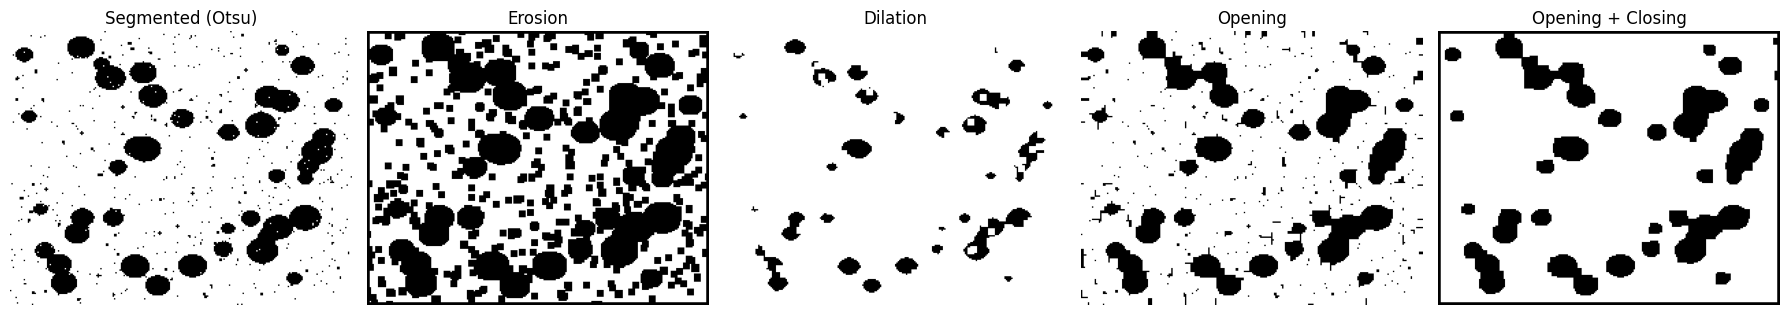

In [46]:
steps = [("Segmented (Otsu)", seg), ("Erosion", eroded), ("Dilation", dilated),
         ("Opening", opened), ("Opening + Closing", final)]

fig, ax = plt.subplots(1, 5, figsize=(18, 4))
for a, (name, im) in zip(ax, steps):
    a.imshow(im, cmap="gray"); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

## 8. Compare: without vs with morphology

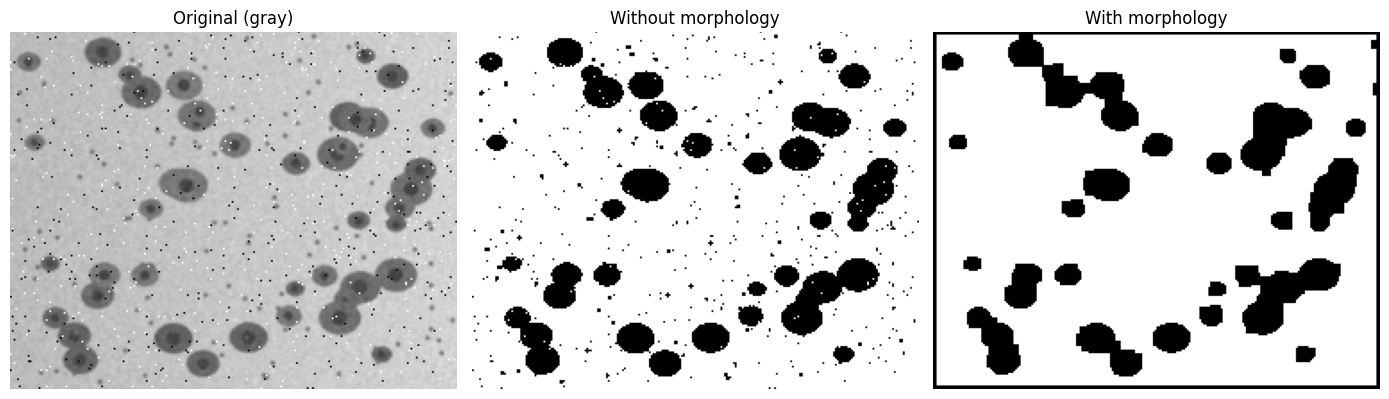

In [47]:
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(gray, cmap="gray");  ax[0].set_title("Original (gray)")
ax[1].imshow(seg, cmap="gray");   ax[1].set_title("Without morphology")
ax[2].imshow(final, cmap="gray"); ax[2].set_title("With morphology")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Numbers


In [48]:
def iou(a, b):
    inter = union = 0
    for ra, rb in zip(a, b):
        for va, vb in zip(ra, rb):
            inter += va and vb
            union += va or vb
    return inter / max(union, 1)

def count_white(img):
    return sum(sum(row) for row in img)

if gt is not None:
    print(f"IoU without morphology: {iou(seg, gt):.3f}")
    print(f"IoU with morphology   : {iou(final, gt):.3f}")
else:
    print("White pixels without morphology:", count_white(seg))
    print("White pixels with morphology   :", count_white(final))

White pixels without morphology: 41792
White pixels with morphology   : 40107
